# Schwarzschild
$f=1-2M/r$. No hair parameter. 

First we have Adam joint fit with (x0, y0, vx0, vy0, vz0) + hair (no hair in Schwarzschild) + NN. 

Then we do Gauss–Newton polish. Adam's hair gradient is not very sensitive how the network's chi(t) responds to the hair: for example Adam alone stops at certain values. So we need something better. Here, each polish step moves orbit, frame and hair together, with that response included (network marginalised), and re-trains the network between steps. The hair value at the end is the network model's prediction- the value that minimises the loss of the GINN model.

Laplace approximation in the end, used only for the error bars and the corner plot.

In every notebook, a cross-check is included but commented-out - one can verify how the network output is comparable with output that does not use network but a numerical solver. 

Also in the end we have tested convergence using different initial values of the hair - it should consistently give a final value within I guess 0.2 sigma whatever the initial guess is. This means good convergence. 

Finally I also list how much the NN has contributed by computing the Fisher information. 

In [1]:
import sys, copy, warnings, dataclasses
sys.path.insert(0, '..')                      # the package lives one level up
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np, torch
import matplotlib.pyplot as plt
%matplotlib inline

from ginn.core import S2Data, keplerian_prefit, LossConfig, train, objective, fit
from ginn.physics import METRICS
from ginn import analysis as an
from ginn import plotting as pl

data = S2Data.from_csv('../data/tab_gillessen_pos.csv', '../data/tab_gillessen_vr.csv')
print(data.summary())

Gillessen+2017: 145 astrometric epochs, 44 RVs, 1992.22-2016.53;  N_data = 334


In [2]:
N_STEPS_GINN   = 3000        # joint fit with orbit (+ hair) + network
N_STEPS_KEPLER = 2000        # pretraining
N_STEPS_EXACT  = 1500        # numerical (just used for comparision)

MODEL = dict(hidden=(32, 32),        # network: 2 hidden tanh layers of 32
             nn_out_scale=1e-3)      
TRAIN = dict(lr_u=0.1,               # Adam step, orbital/hair parameters 
             lr_nn=5e-4,             # network weights  (if we increase to 2e-3 we get oscillating spikes)
             lr_floor=0.01,          # cosine decay to lr_floor x initial
             precondition=(0.0,))    # Gauss-Newton computed once, at step 0

cfg = LossConfig(eps_phys=1e-4,      # physics weight (inverse). This is not random. We do a scan below. 
                 n_colloc=256,       # collocation points over one period
                 sigma_w=10.0)       # weak Gaussian prior on network weights (for Laplace - see paper draft)

FRAME = ['x0', 'y0', 'vx0', 'vy0', 'vz0']
LIT = {'inc': 134.18, 'Omega': 226.94, 'omega': 65.51}  # used for reference only

METRIC    = 'schwarzschild'
HAIR_INIT = {}   # No hair 

#-----------some unimportant things
FIXED     = ()        # parameters held fixed throughout
SCAN      = None   # (name, [values]) of a fixed parameter to repeat the fit
N_STEPS_WARM = 1000        # re-fit of orbit + network at each new value
HOLD_HAIR_IN_ADAM = False  # False - hair free in Adam + polish.
                           # True: hair held during Adam, freed for the polish (only needed if Adam drives the hair far off, like in Yukawa).
#-----------

GN = dict(n_iter=30,       # max Gauss-Newton polish steps (stops earlier if converged)
          n_retrain=400,   # network re-training between steps (hair held)
          tol=0.02,        # stop when the predicted chi2 gain < tol
          lr_nn=2e-3)      
USE_FSP = False            # add precession f_SP = 1.10 +- 0.19

CORNER = dict(n_samples=200_000,   # Laplace samples (more samples means smoother contours)
              bins=40,             # histogram bins per axis
              smooth=1.5)          # Gaussian smoothing of the 2-D histograms (in bins)
metric = METRICS[METRIC]
if USE_FSP:
    cfg = dataclasses.replace(cfg, external_precession=(1.10, 0.19))
HOLD = tuple(hp.name for hp in metric.hair if hp.name not in FIXED)
for hp in metric.hair: print(hp)

In [3]:
# Comparing analytic precession vs numerical - not neeeded


# from ginn.physics import orbit_constants, M_SUN_GEOM_AU
# M_, a_, e_ = torch.tensor(4.26e6 * M_SUN_GEOM_AU), torch.tensor(1031.2), torch.tensor(0.8846)
# gr = 6 * np.pi * M_ / (a_ * (1 - e_**2))
# for hp in metric.hair:
#     for v in np.linspace(hp.prior.lo, hp.prior.hi, 5):
#         par = {h.name: torch.tensor(float(v if h.name == hp.name else HAIR_INIT.get(h.name, h.init))) for h in metric.hair}
#         d = orbit_constants(metric, a_, e_, par, M_)[3]; an_ = metric.precession(M_, a_, e_, par)
#         print(f"{hp.name} = {v:9.4g}: f_SP exact {(d/gr).item():9.4f}   analytic {(an_/gr).item():9.4f}")

## Pretraining

Keplerian pre-fit (astrometry only): chi2 = 297.4
  M=4.1419e+06, a=1023.6, e=0.87929, inc=134.79, Omega=224.95, omega=63.536, t0=2002.3, D=8.3, P=16.0909 yr


schwarzschild/ginn:   0%|          | 0/3000 [00:00<?, ?it/s]

after Adam: M = 4.2107e6 Msun | a = 1030.07 AU | e = 0.88725 | i = 134.088 | Om = 227.396 | om = 65.883 | t_p = 2002.3285 | D = 8.0784 kpc | vz0 = 10.25 km/s
   frame: x0 = +0.720 mas | y0 = -2.488 mas | vx0 = +0.1210 mas/yr | vy0 = +0.0119 mas/yr


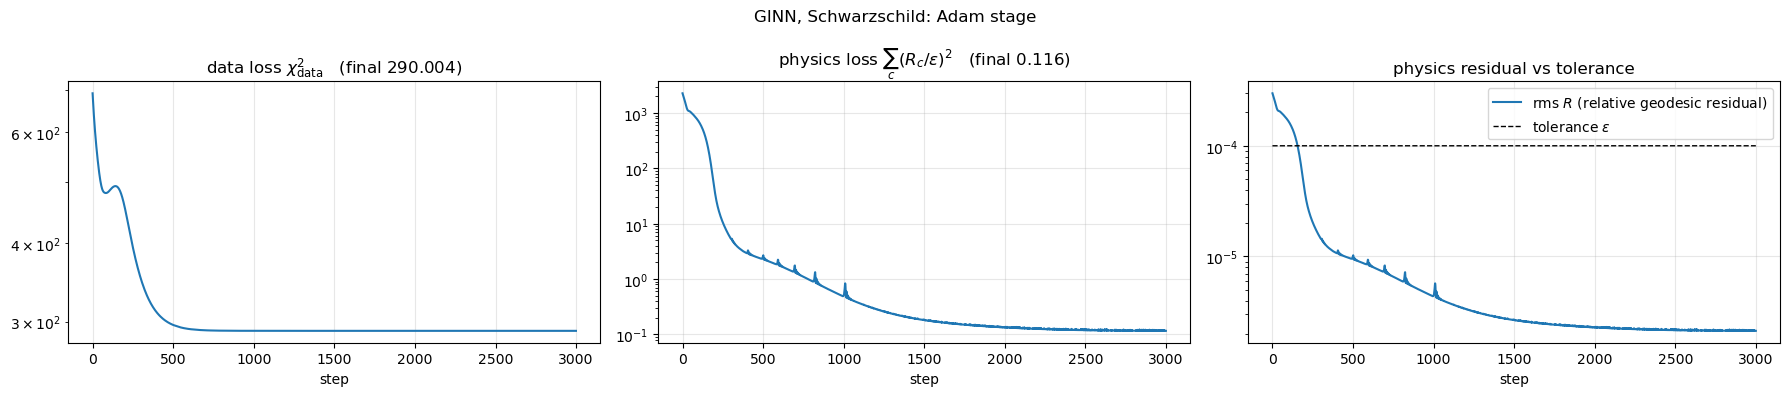

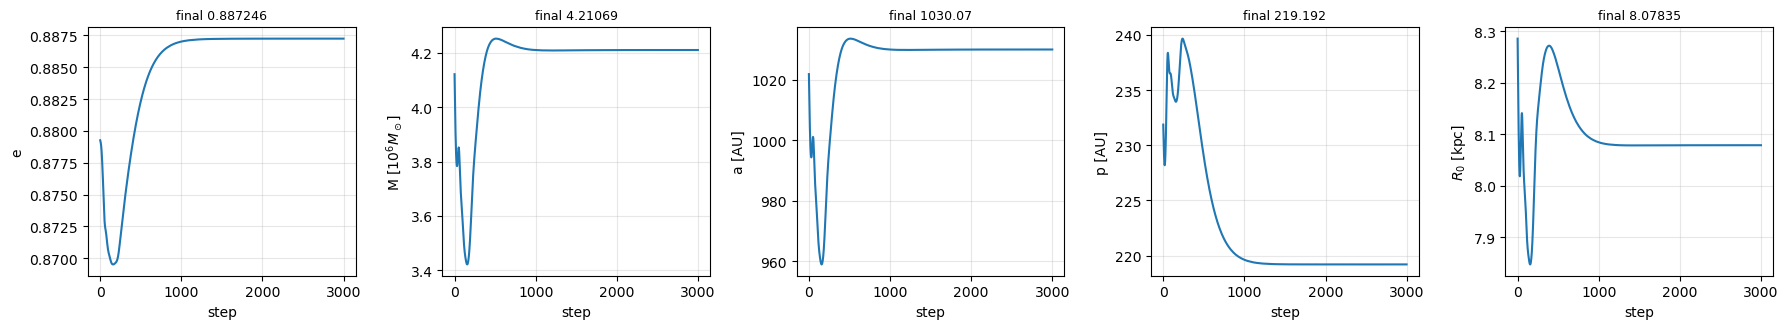

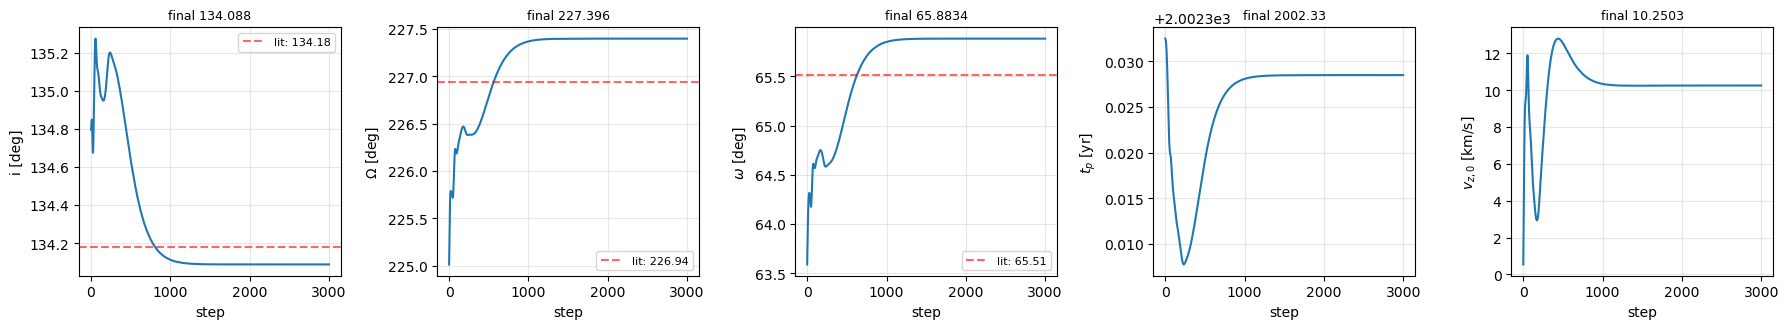

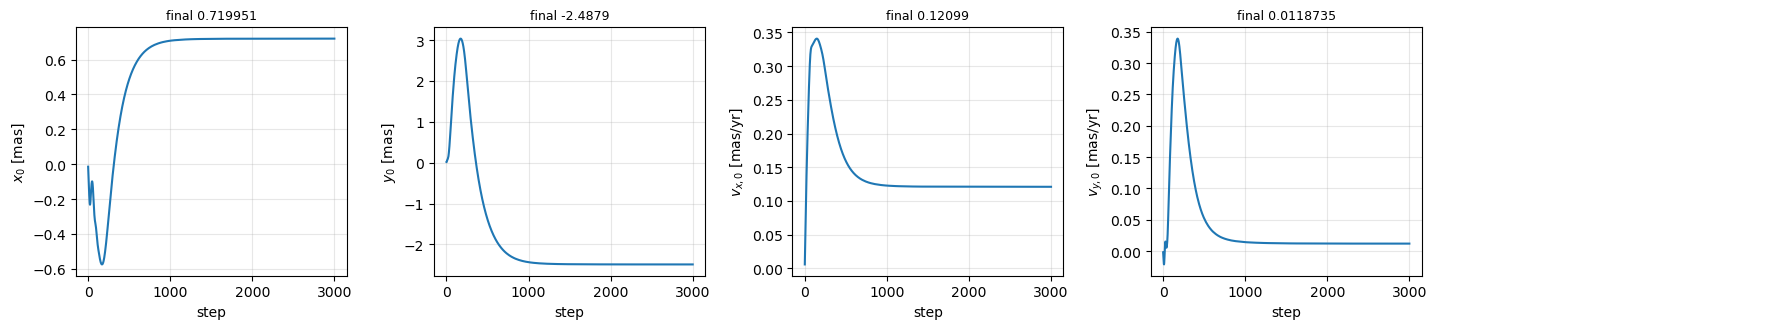

In [4]:
init = keplerian_prefit(data)
ginn, hist = fit(metric, data, init, timing='ginn', cfg=cfg, n_steps=N_STEPS_GINN,
                 hair_init=HAIR_INIT, fixed=tuple(set(HOLD) | set(FIXED)) if HOLD_HAIR_IN_ADAM else FIXED,
                 **MODEL, **TRAIN)
if HOLD_HAIR_IN_ADAM:
    for h in HOLD:
        ginn.fix(h, fixed=False)                 # release the hair for the polish
print('after Adam:', ginn.summary())
pl.plot_loss_history(hist, f'GINN, {metric.label}: Adam stage'); plt.show()
pl.plot_param_history(hist, lit=LIT); plt.show()

## Gauss–Newton polish

In [5]:
lap, gn_hist = an.gn_polish(ginn, data, cfg, **GN)
print('\nafter polish:', ginn.summary())
if HOLD:
    fig, ax = plt.subplots(1, 1 + len(HOLD), figsize=(6 * (1 + len(HOLD)), 3.5))
    ax[0].semilogy([max(h['chi2_gain'], 1e-4) for h in gn_hist], 'o-'); ax[0].axhline(GN['tol'], color='k', ls='--')
    ax[0].set_title('predicted chi2 gain per step (converged below dashed line)'); ax[0].set_xlabel('GN step')
    for a_, h in zip(ax[1:], HOLD):
        a_.plot([x[h] for x in gn_hist], 'o-'); a_.set_title(f'{h} during the polish'); a_.set_xlabel('GN step')
    plt.tight_layout(); plt.show()

C:\Users\phys6\Downloads\GINN_final\GINN\notebooks\..\ginn\analysis.py:99: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  chi2=float((r ** 2).sum()), marginalized=use_nn, timing=timing,


GN 0: predicted chi2 gain    0.000   

after polish: M = 4.2107e6 Msun | a = 1030.07 AU | e = 0.88725 | i = 134.088 | Om = 227.396 | om = 65.883 | t_p = 2002.3285 | D = 8.0784 kpc | vz0 = 10.25 km/s
   frame: x0 = +0.720 mas | y0 = -2.488 mas | vx0 = +0.1210 mas/yr | vy0 = +0.0119 mas/yr


## Results

In [6]:
post = an.posterior(ginn, data, cfg)
est = an.print_estimates(ginn, post)
S = an.sample_laplace(ginn, post, n=CORNER['n_samples'])
print()
for k in ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + FRAME:
    m_, lo_, hi_ = an.summarize(S)[k]; print(f"{k:6s} = {m_:.6g} +- {0.5 * (lo_ + hi_):.3g}")


M      = 4.21047 +- 0.23
D      = 8.07851 +- 0.228
a      = 127.507 +- 1.39
e      = 0.887245 +- 0.0028
inc    = 134.087 +- 0.553
Omega  = 227.395 +- 0.732
omega  = 65.8821 +- 0.731
t0     = 2002.33 +- 0.00633
x0     = 0.719136 +- 0.221
y0     = -2.48541 +- 0.667
vx0    = 0.120944 +- 0.0459
vy0    = 0.0119894 +- 0.0728
vz0    = 10.2213 +- 7.8


In [7]:
# save the best fit and its posterior (used by compare_orbits.ipynb and 00_validation_and_checks.ipynb)
import os
os.makedirs('results', exist_ok=True)
torch.save(dict(model=ginn, hair=est, post=post, cfg=cfg), f'results/{METRIC}.pt')
print(f'saved results/{METRIC}.pt')

saved results/schwarzschild.pt


## Bayesian evidence
Laplace estimate of the evidence, from the same curvature as the error bars, relative to Schwarzschild (run 01_schwarzschild first). $\ln B>0$ favours this spacetime; the Occam term depends on the width of the hair prior.

In [8]:
ev = an.evidence(ginn, data, cfg, post)
r_ = torch.load(f'results/{METRIC}.pt', weights_only=False)
r_['evidence'] = ev
torch.save(r_, f'results/{METRIC}.pt')
ref_file = 'results/schwarzschild.pt'
ref = torch.load(ref_file, weights_only=False) if os.path.exists(ref_file) else {}
if METRIC == 'schwarzschild':
    print(f"chi2 = {ev['chi2']:.3f},   ln det Sigma = {ev['logdet_rest']:.3f}   (reference for all Bayes factors)")
elif 'evidence' in ref:
    an.print_bayes(metric.label, an.bayes_factor(ev, ref['evidence']))
else:
    print('run 01_schwarzschild.ipynb first: it provides the reference evidence')

chi2 = 290.004,   ln det Sigma = -116.320   (reference for all Bayes factors)


## Corner plots

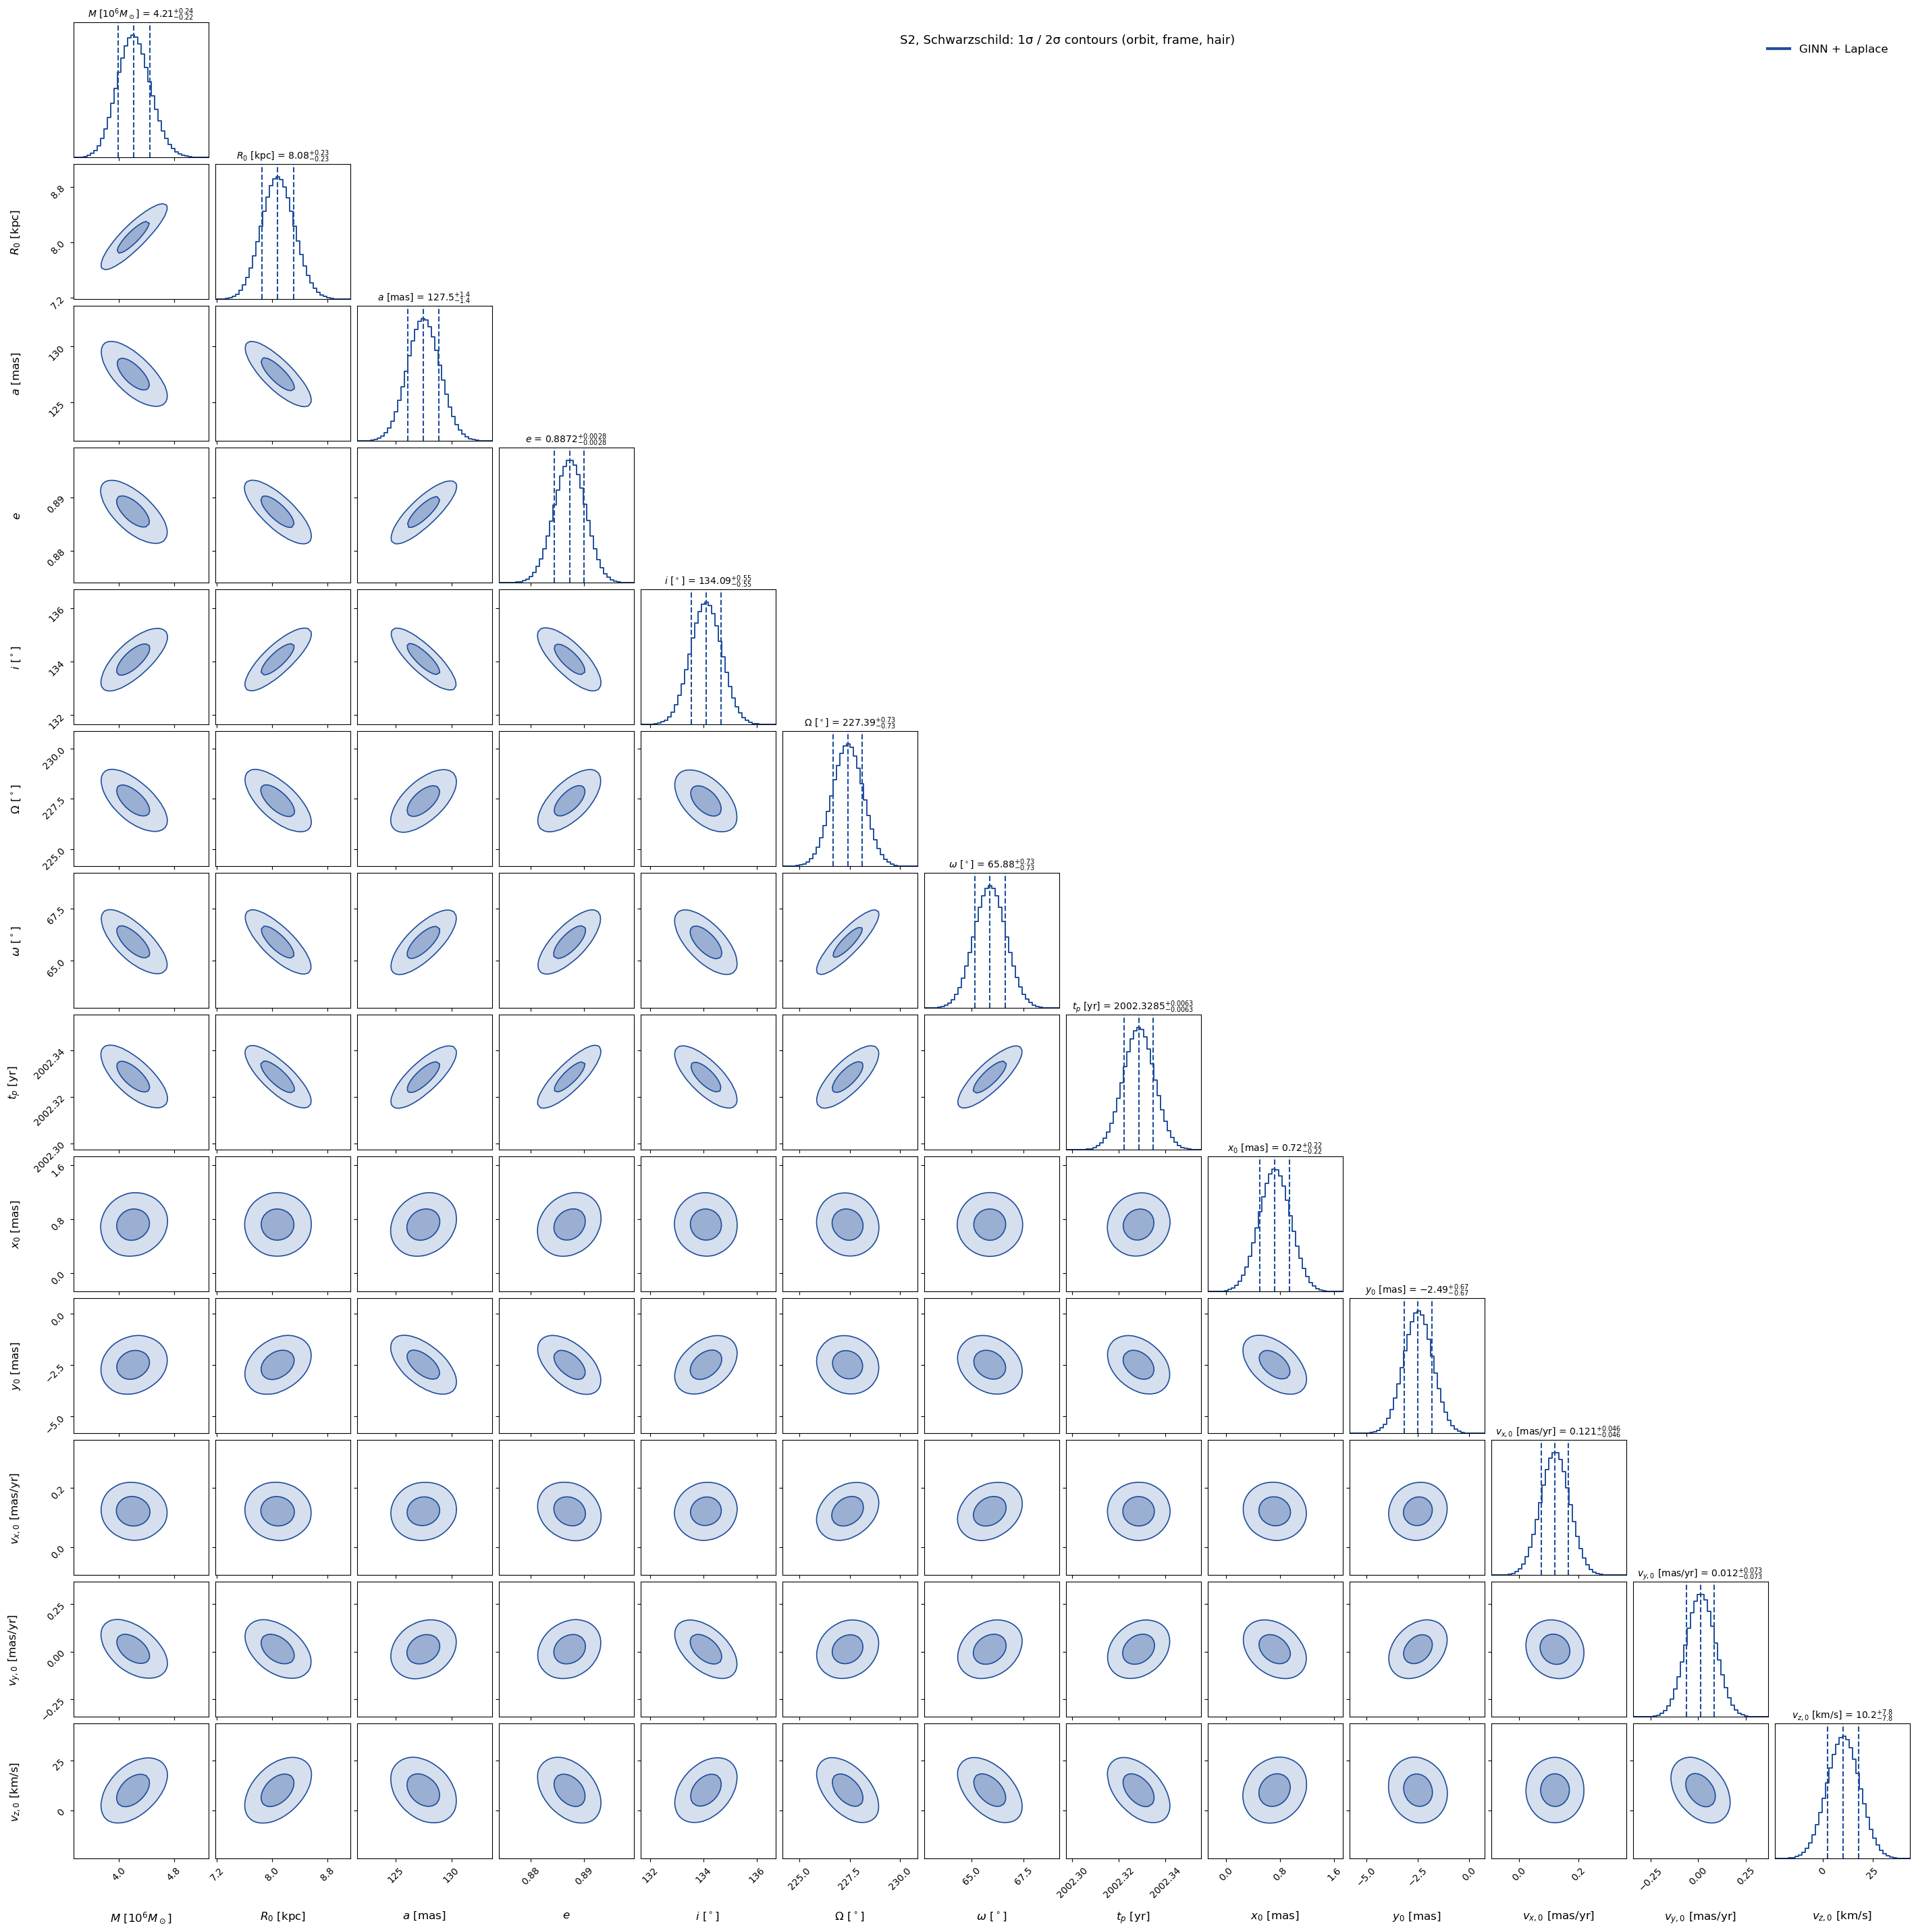

In [9]:
# one corner plot with ALL fitted parameters: orbit, hair and reference-frame offsets
keys = ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + FRAME + list(HOLD)   # ALL parameters, one plot
pl.corner_plot([S], an.labels_for(ginn), keys, names=['GINN + Laplace'],
               bins=CORNER['bins'], smooth=CORNER['smooth'],
               title=f'S2, {metric.label}: 1σ / 2σ contours (orbit, frame, hair)')
plt.savefig("corner_01_schwarz")
plt.show()

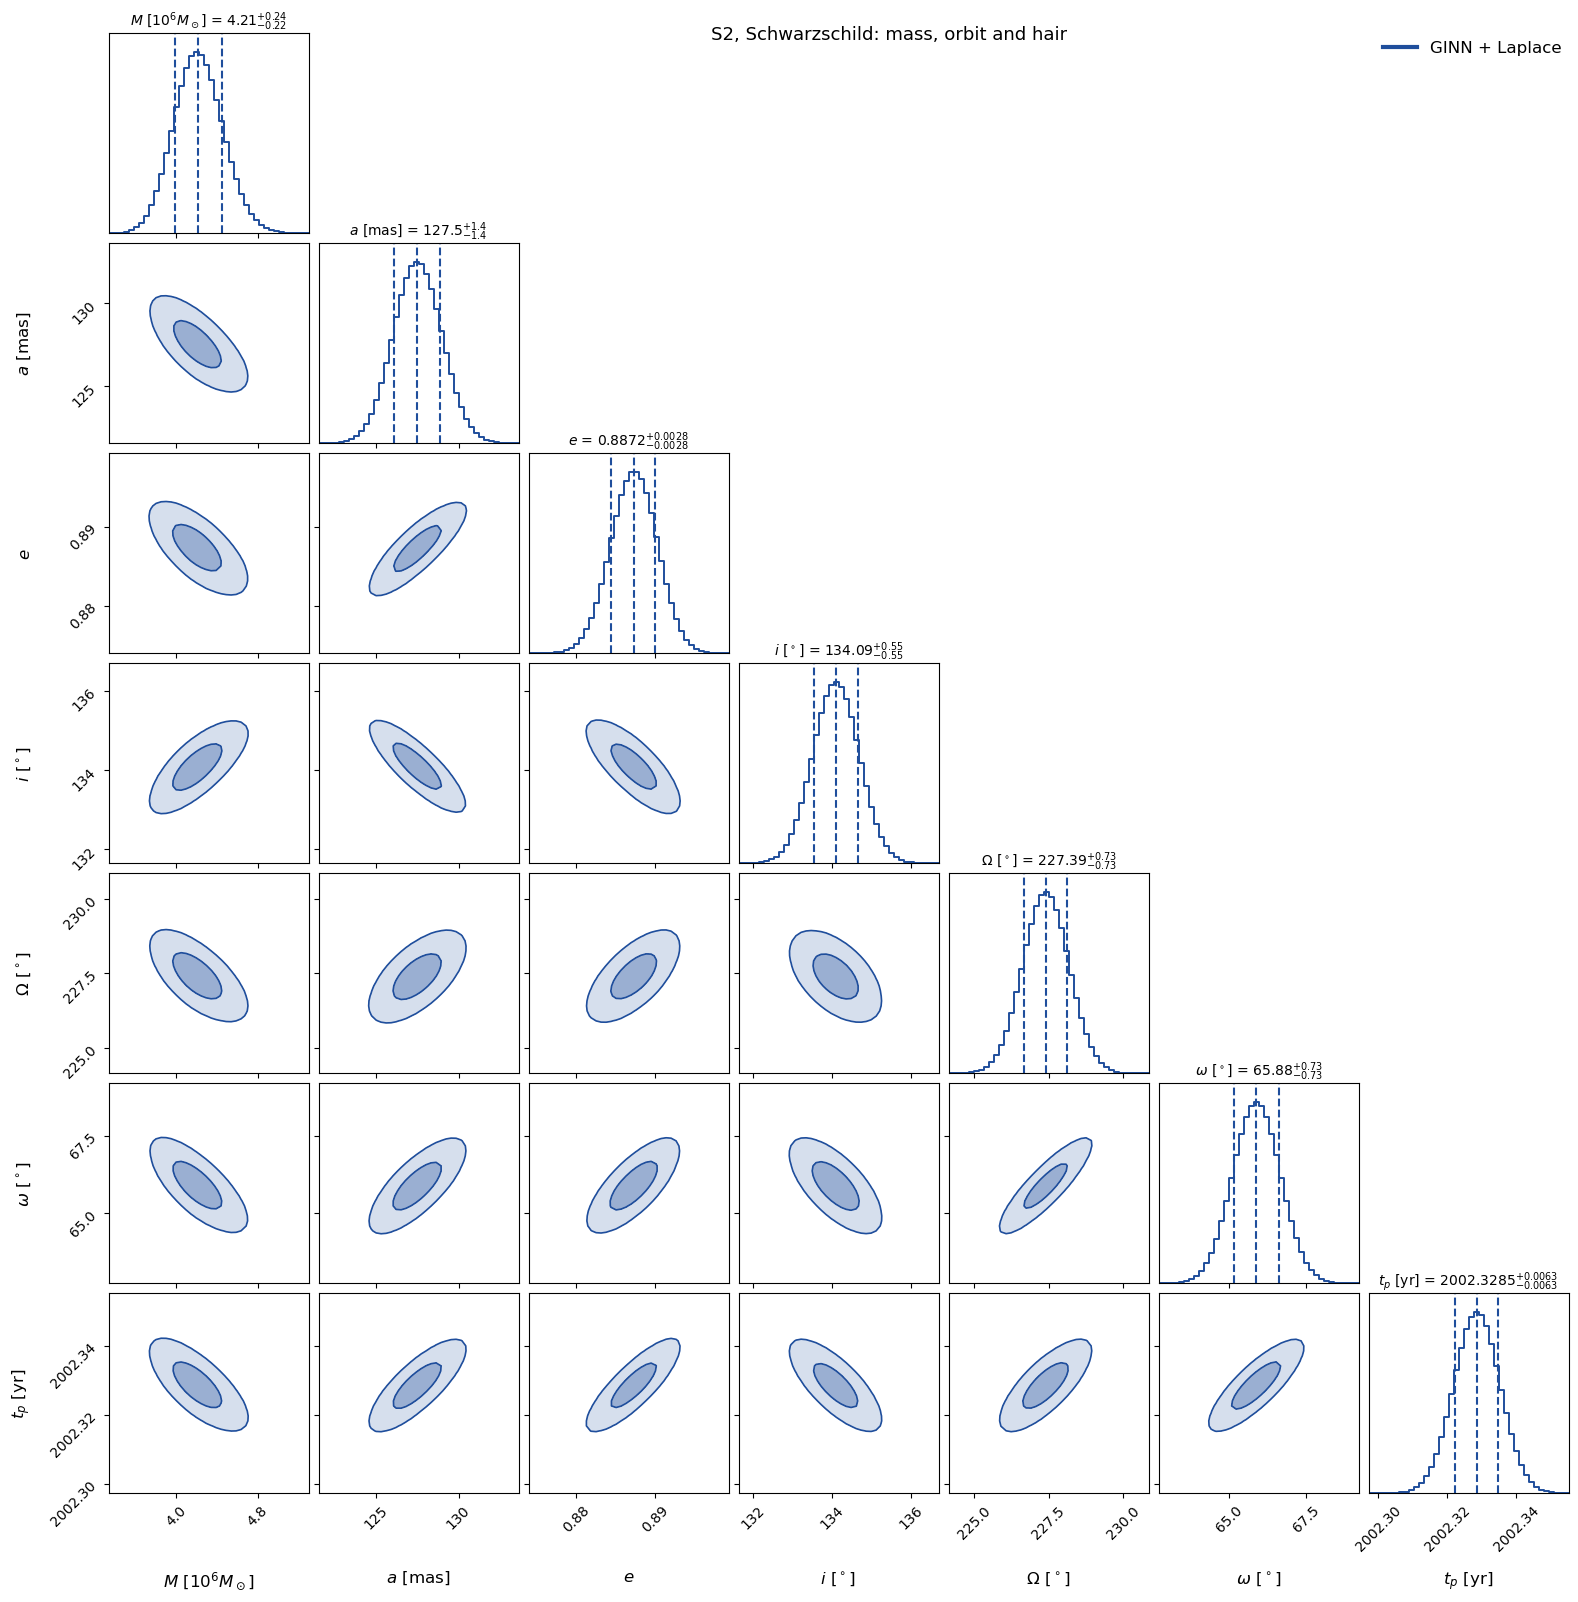

In [10]:
keys_red = ['M', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + list(HOLD)
pl.corner_plot([S], an.labels_for(ginn), keys_red, names=['GINN + Laplace'],
               bins=CORNER['bins'], smooth=CORNER['smooth'],
               title=f'S2, {metric.label}: mass, orbit and hair')
plt.savefig("small_corner_01_schwarz")
plt.show()

In [11]:
# pl.plot_convergence(hist, S, gn_hist if HOLD else None, title=f'{metric.label}: convergence');plt.show()

In [12]:
# keep the posterior samples for the summary plots in 09_compare_orbits
import os
res_file = f'results/{METRIC}.pt'
if os.path.exists(res_file):
    r_ = torch.load(res_file, weights_only=False)
    r_['samples'] = {k: np.asarray(v)[:20000] for k, v in S.items()}
    torch.save(r_, res_file)

## Beyond the quadratic approximation
The data residuals are expanded to second order in the physical parameters, with the network eliminated to the same order, so that $\chi^2$ contains terms up to fourth order. This posterior is sampled with MCMC and compared with the Gauss–Newton + Laplace result above: shifts of the mean in units of the Laplace $\sigma$, ratio of the widths, and skewness. The comparison with the exact geodesic solver is in 00_validation_and_checks.

higher-order MCMC: 3022 effective samples

             Gauss-Newton + Laplace |        dali: shift, sd ratio, skew
M               4.21675 +- 0.231     |      +0.07       0.953       +0.17 |
D                8.0813 +- 0.228     |      +0.07       0.931       +0.03 |
a               127.519 +- 1.39      |      -0.07       0.922       +0.16 |
e              0.887217 +- 0.0028    |      -0.06       0.929       +0.08 |
inc             134.087 +- 0.554     |      +0.07       0.925       +0.02 |
Omega           227.397 +- 0.73      |      -0.09       0.943       +0.06 |
omega           65.8846 +- 0.731     |      -0.10       0.929       +0.05 |
t0              2002.33 +- 0.00634   |      -0.12       0.922       -0.04 |


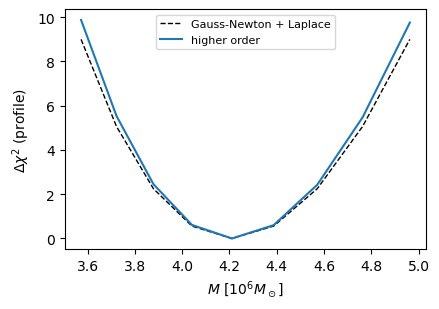

In [13]:
from ginn import higher_order as ho
HO_KEYS = ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + list(HOLD)
P = ho.Expansion(ginn, data, post, cfg).expand()
chain = ho.sample(P, 'dali', n=600_000)
st = {'laplace': ho.stats(ho.sample(P, 'laplace'), HO_KEYS), 'dali': ho.stats(chain, HO_KEYS)}
print(f"higher-order MCMC: {chain['n_eff']:.0f} effective samples\n")
ho.print_compare(st, HO_KEYS, names=('dali',), hair=list(HOLD))
names = list(HOLD) or ['logM']
fig, axs = plt.subplots(1, len(names), figsize=(4.5 * len(names), 3.2), squeeze=False)
for a_, nm in zip(axs[0], names):
    pr = ho.profile(P, nm)
    if nm == 'logM':
        ho.plot_profile(a_, pr, label=r'$M\ [10^6 M_\odot]$', transform=lambda x: np.exp(x) / 1e6)
    else:
        ho.plot_profile(a_, pr, label=an.labels_for(ginn)[nm])
axs[0][0].legend(fontsize=8); plt.tight_layout(); plt.show()
r_ = torch.load(f'results/{METRIC}.pt', weights_only=False)
r_['higher_order'] = st
torch.save(r_, f'results/{METRIC}.pt')

## Some comparision and validations

chi2 (N_data = 334)                     RA      Dec      RV     total
  GINN                                         140.75   137.68   11.56   290.004
  without network                              140.78   137.79   11.53   290.096
  geodesic timing numerical                    140.76   137.68   11.56   290.002
we compare chi-squared improvement due to GINN and exact numerical correction - should be more or less equal


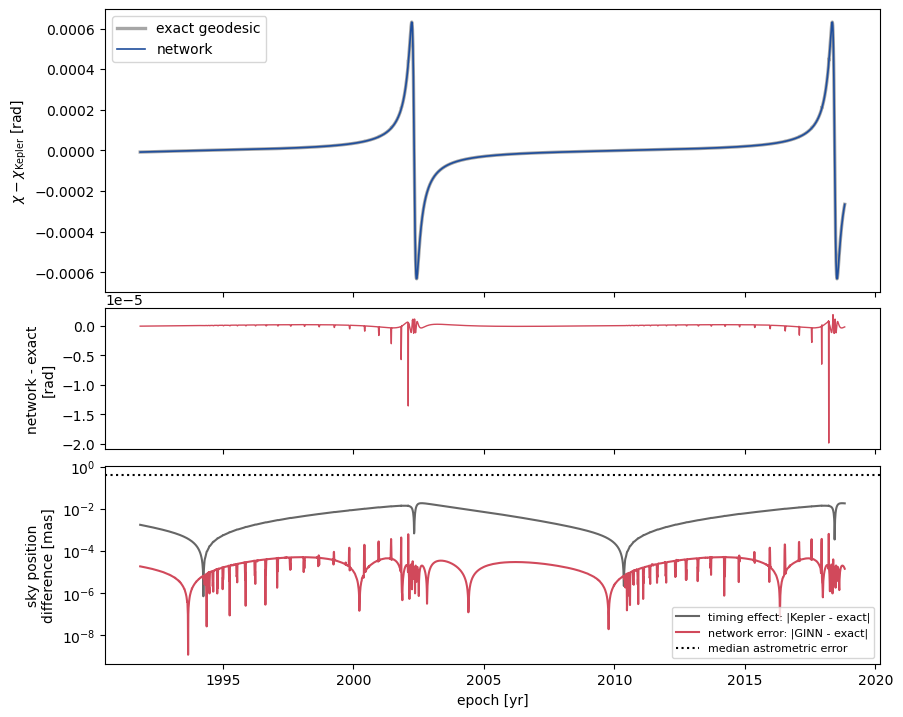

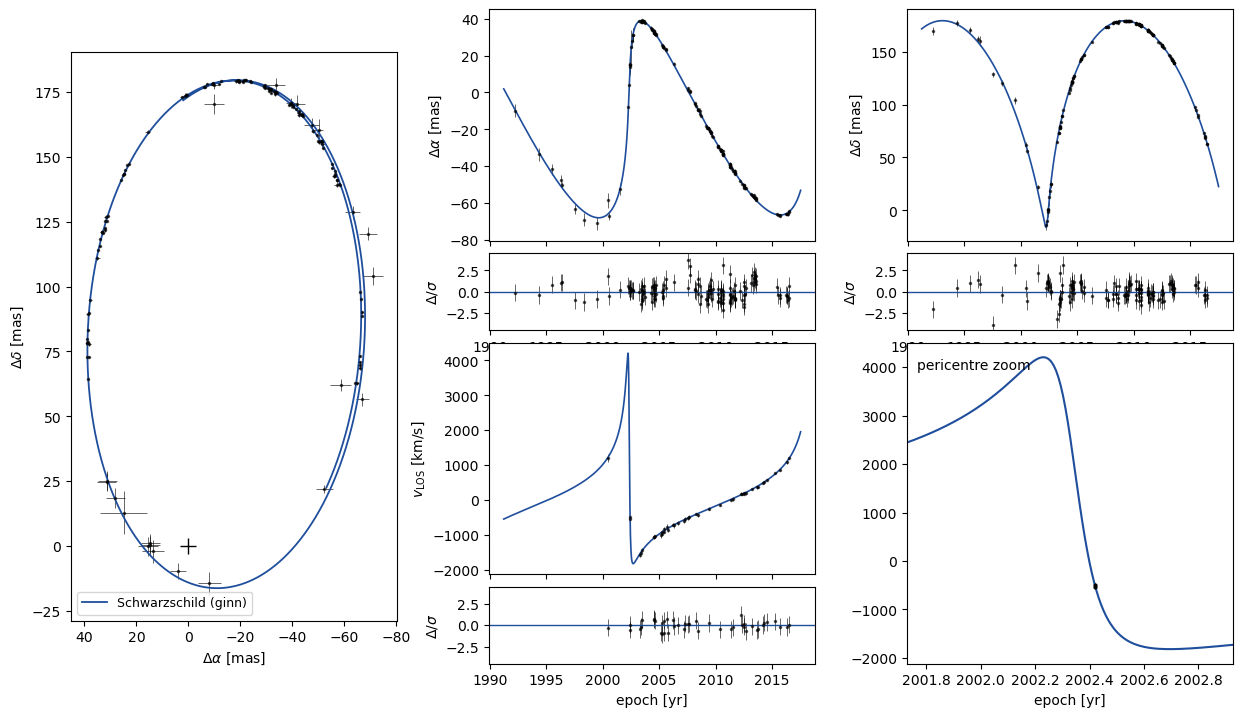

In [14]:
rep = an.nn_role_report(ginn, data, cfg, lap=post)
pl.plot_timing(rep['timing_curves'], data); plt.show()
pl.plot_fit(ginn, data); plt.show()

In [15]:
# exact, _ = fit(metric, data, init, timing='exact', cfg=cfg, n_steps=N_STEPS_EXACT,
#                hair_init=HAIR_INIT, fixed=FIXED, **TRAIN)
# lap_ex = an.laplace(exact, data, cfg)
# print('exact solver:', exact.summary())
# print('exact solver hair:', an.hair_estimates(exact, lap_ex))

## Multi-start consistency 
The full procedure is run again from several starting values of the hair parameter. Here we do not have hair, so the network's random seed is varied instead. The result after Adam and after the polish is printed. The estimate is accepted only if the spread of the final values is < 0.2σ.


In [16]:
RUN_MULTISTART = True
MULTI_STARTS = [0, 1, 2]
ms_rows = []
if RUN_MULTISTART:
    for s0 in MULTI_STARTS:
        if HOLD:
            hi, seed = {**HAIR_INIT, HOLD[0]: s0}, 0
        else:
            hi, seed = HAIR_INIT, int(s0)
        m_, h_ = fit(metric, data, init, timing='ginn', cfg=cfg, n_steps=N_STEPS_GINN, hair_init=hi,
                     fixed=FIXED, seed=seed, progress=False, **MODEL, **TRAIN)
        adam = {k: float(m_.physical()['par'][k]) for k in HOLD}
        chi2_adam = an.chi2_parts(m_, data)['total']
        lap_, gh_ = an.gn_polish(m_, data, cfg, verbose=False, **GN)
        post_ = an.posterior(m_, data, cfg, verbose=False)
        S_ = an.sample_laplace(m_, post_, n=20000, verbose=False)
        row = dict(start=s0, adam=adam, chi2_adam=chi2_adam, est=an.hair_estimates(m_, post_),
                   chi2=an.chi2_parts(m_, data)['total'], steps=len(gh_),
                   M=an.summarize(S_)['M'], D=an.summarize(S_)['D'])
        ms_rows.append(row)
        txt = '  '.join(f"{k}: Adam {row['adam'][k]:+.5g} -> polish {row['est'][k][0]:+.5g} +- {row['est'][k][1]:.3g}" for k in HOLD)
        print(f"start {s0:+g}: {txt}  | M = {row['M'][0]:.4f}, R0 = {row['D'][0]:.4f} | chi2 Adam {chi2_adam:.2f} -> {row['chi2']:.2f} ({row['steps']} GN steps)")
    def spread(vals, sig):
        return (max(vals) - min(vals)) / sig
    sym = lambda k, v: abs(v) if k in an.SQUARED_HAIR else v
    checks = [(k, [sym(k, r['est'][k][0]) for r in ms_rows], np.mean([r['est'][k][1] for r in ms_rows])) for k in HOLD]
    checks += [('M', [r['M'][0] for r in ms_rows], np.mean([0.5 * (r['M'][1] + r['M'][2]) for r in ms_rows])),
               ('R0', [r['D'][0] for r in ms_rows], np.mean([0.5 * (r['D'][1] + r['D'][2]) for r in ms_rows]))]
    print()
    for k, vals, sig in checks:
        sp = spread(vals, sig)
        print(f"{k:>14s}: spread across starts = {sp:.2f} sigma  ->  " +
              ('CONSISTENT' if sp < 0.2 else 'NOT CONSISTENT (increase N_STEPS_GINN or GN n_iter)'))
    if HOLD:
        k = HOLD[0]
        fig, ax = plt.subplots(figsize=(7, 4))
        xs = np.arange(len(ms_rows))
        ax.errorbar(xs, [r['est'][k][0] for r in ms_rows], [r['est'][k][1] for r in ms_rows], fmt='o',
                    color='#1f4e9c', capsize=4, label='after polish (± Laplace)')
        ax.plot(xs, [r['adam'][k] for r in ms_rows], 'x', color='0.4', label='after Adam')
        ax.plot(xs, [r['start'] for r in ms_rows], '.', color='#d1495b', label='start value')
        ax.set_xticks(xs); ax.set_xticklabels([f"start {r['start']:+g}" for r in ms_rows])
        ax.set_ylabel(k); ax.legend(fontsize=9); ax.set_title('multi-start consistency'); plt.show()

start +0:   | M = 4.2137, R0 = 8.0828 | chi2 Adam 290.00 -> 290.00 (1 GN steps)
start +1:   | M = 4.2139, R0 = 8.0829 | chi2 Adam 290.00 -> 290.00 (1 GN steps)
start +2:   | M = 4.2134, R0 = 8.0826 | chi2 Adam 290.00 -> 290.00 (1 GN steps)

             M: spread across starts = 0.00 sigma  ->  CONSISTENT
            R0: spread across starts = 0.00 sigma  ->  CONSISTENT
